In [1]:
import sys
print(sys.executable)
sys.path.append('/home/nhewko/FEniCS/swelling/vf-swelling-fiber')
sys.path.append('/home/nhewko/FEniCS/swelling/vf-exputils')
sys.path.append('/home/nhewko/FEniCS/swelling/vf-fem')
sys.path.append('/home/nhewko/FEniCS/swelling/nonlinear-equation')
sys.path.append('/home/nhewko/FEniCS/vf-onset-sensitivity/src/libhopf')
sys.path.append('/home/nhewko/FEniCS/vf-onset-sensitivity/')
import libhopf

/home/nhewko/miniconda3/envs/fenics-env/bin/python


# Baseline Parameters Definition

In [2]:
import itertools
import os, sys
from pprint import pprint
from typing import Mapping, Any, List, Tuple, Union
from tqdm.notebook import tqdm

import numpy as np
import scipy.signal as signal
import dolfin as dfn
import ufl
import h5py
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import tri
# pandas used for exporting values to csv
import pandas as pd

from femvf import forward, statefile as sf, meshutils
from femvf.models.transient import solid, fluid
from femvf.models.dynamical import (solid as dsolid, fluid as dfluid)
from femvf.postprocess import solid as slsig
from femvf import static
from femvf.load import load_transient_fsi_model, load_dynamical_fsi_model

from blockarray import blockvec

from vfsig import modal, fftutils, clinical

from exputils import h5utils, exputils, postprocutils
import scar

sys.path.append('../vf-onset-sensitivity')
import libhopf

dfn.set_log_level(50)

ExpParam = scar.ExpParam

## Default parameter values
# Change values here to reflect recently run simulations
# (can refer to output folder to obtain values) 
PARAMS_DEFAULT = ExpParam({
    'MeshName': 'BCS_M',
    'SD': 0.08,
    'DZ': 0.00, # Spacing in Z axis
    'NZ': 1, # Number of segments in Z direction
    'clscale': 0.25,
    'Ecov': 2.5e4, # Ecover (Pa)
    'Ebod': 5e4, # Ebody (Pa)
    'ModScar': 10, # Scarring Modifier
    'Eta': 5, # Viscosity
    'psub': 0.3e3 * 10, # Subglottal pressure (kPa)
    'dt': 2.5e-5, # Timestep size
    'tf': 1, # Simulation end time 
    'ModifyEffect': '',
    'SwellingDistribution':'uniform'
})

SAVE_FIGS = True

# The order of which different scar locations are displayed. If a MeshName is not present, then the entry from here is ignored
# Any new MeshNames need to be added in this list
MESH_NAMES = ['BCS_S', 'BCS_M', 'BCS_I']

# set output file location 
OUT_DIR = 'out'
POST_DIR = OUT_DIR

#set variables for saving images to svg
FIG_DIR = 'fig'
FIG_EXT = 'svg'

def iter_params(
    
        params: Mapping[str, Union[List[Any], Any]],
        default_params: ExpParam=PARAMS_DEFAULT
    ):
    '''
    Return an iterator over `ExpParam` instances

    Parameters
    ----------
    params :
        A mapping from parameter labels to parameter value(s). Parameter
        instances are created for each parameter value given in the dictionary.
    defaults : ExpParam
        Default values for unspecified parameters
    '''
    # Validate that all kwargs keys are valid parameters
    keys = list(params.keys())
    for key in keys:
        assert key in default_params

    # Make sure all parameter values are lists
    # This is so that you can iterate over them
    def _require_list(x):
        if isinstance(x, (list, tuple, np.ndarray)):
            return x
        else:
            return [x]

    _params = {
        key: _require_list(values)
        for key, values in params.items()
    }

    def _param(params):
        x = default_params.data.copy()
        x.update(params)
        return type(default_params)(x)

    for args in itertools.product(*list(_params.values())):
        yield (
            _param({key: val for key, val in zip(keys, args)})
        )

def load_measures(
        data: Mapping[str, Any],
        measure_name: str,
        params: Mapping[str, Union[List[Any], Any]],
        default_params: ExpParam=PARAMS_DEFAULT
    ):
    '''
    Return measures for each supplied parameter(s)

    Parameters
    ----------
    data :
        A mapping from simuations ids/measure names to values
    measure_name : str
        A measure name to load
    params :
        A mapping from parameter labels to parameter value(s). Measurements
        are extracted from these parameters.
    defaults :
        Default values for unspecified parameters
    '''
    keys = list(params.keys())
    vals = [
        data[f'{param.to_str()}/{measure_name}']
        for param in iter_params(params, default_params=default_params)
        
    ]
    if len(vals) == 1:
        return vals[0]
    else:
        return vals

def load_measures_np(
        data: Mapping[str, Any],
        measure_name: str,
        params: Mapping[str, Union[List[Any], Any]],
        default_params: ExpParam=PARAMS_DEFAULT
    ):
    '''
    Return measures for each supplied parameter(s) (see `load_measures`)

    This functions returns outputs in a numpy array
    '''
    return np.array(load_measures(data, measure_name, params, default_params))



## Load post-processed results

In [3]:
SIGNALS = {}

## Load simulation results, if error with case_names later, delete postprocess.h5 and run simulations again to clear 'cached' simulations in POST_DIR folder
with h5py.File(f'{POST_DIR}/postprocess.h5', mode='r') as f:
    SIGNALS = h5utils.h5_to_dict(f, SIGNALS)
    

In [4]:
# Get a text summary of what cases were run and what measures were processed
from pprint import pprint
# case_names refer to each of the simulation names, the long file names in the 'out' folder
# an entry in case_names can also be called instead by PARAMS[].to_str(), useful for nested for loops being used for multi-param sweeps 
case_names = [key.split('/')[0] for key in SIGNALS.keys()]
case_names = list(set(case_names))

# List of parameters that are saved in each simulation (mostly output parameters)
meas_names = [key.split('/')[1] for key in SIGNALS.keys()]
meas_names = list(set(meas_names))

## Loading Model Info

In [5]:
from femvf.meshutils import sort_vertices_by_nearest_neighbours
# Generate empty arrays for mesh names and scar diameters in study to be populated based on the current set of simulations
MeshNames = []
ScarDias = []

# Iterate through all the cases in the 'out' folder (but not in subfolders)
for case_name in tqdm(case_names):
    # Check if the current mesh name (mesh type) is not in the list of cases
    if scar.ExpParam(case_name)['MeshName'] not in MeshNames:
        MeshNames.append(scar.ExpParam(case_name)['MeshName'])

    if scar.ExpParam(case_name)['SD'] not in ScarDias:
        ScarDias.append(scar.ExpParam(case_name)['SD'])

# Sorting MeshNames
# If missing a MeshName, make sure the array in baseline params definition is updated
MeshNames_sorted = []
for MeshOrder in MESH_NAMES:
    if MeshOrder in MeshNames:
        MeshNames_sorted.append(MeshOrder)
MeshNames = MeshNames_sorted

# Sort SD array from smallest to largest to be proper and avoid issues with plotting
SD_sorted = np.stack((ScarDias), axis=0)
np_ScarDias = SD_sorted[SD_sorted.argsort()][::1]
# Copy sorted numpy SD array to the regular SD array, required for searching
for itr in range(0, len(ScarDias), 1):
    ScarDias[itr] = float(np_ScarDias[itr])

PARAMS = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
CASE_NAMES = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
MODEL = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
XREF = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
SDOF_TO_VERT = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
VERT_TO_VDOF = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
VERT_TO_SDOF = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
MESH = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
CELLS = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]

VERT_MED = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
VERT_INT = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
VERT_SCAR_INT = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))] # scar vertices along interface
VERT_SCAR_BORDER = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))] # scar vertices along interface and at cover 
VERT_SCAR = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))] # all vertices in scar region
CELLS_SCAR = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]

V_CG1 = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
DOFMAP_CG1 = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
V_DG0 = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
DOFMAP_DG0 = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]

for iM in range(0, len(MeshNames)):
    for iS in range(0, len(ScarDias)):
        # Substituting default meshname and scardia values with the currently iterated ones
        PARAMS[iM][iS] = PARAMS_DEFAULT.substitute({
            # Obtaining value from index of each property to avoid using 'MeshNames.index(iM)' for every index call
            'MeshName': MeshNames[iM],
            'SD': ScarDias[iS]
        })
        MODEL[iM][iS] = scar.setup_model(PARAMS[iM][iS])

        XREF[iM][iS] = MODEL[iM][iS].solid.XREF
        SDOF_TO_VERT[iM][iS] = dfn.dof_to_vertex_map(MODEL[iM][iS].solid.residual.form['coeff.fsi.p1'].function_space())
        VERT_TO_VDOF[iM][iS] = dfn.vertex_to_dof_map(MODEL[iM][iS].solid.residual.form['coeff.state.u1'].function_space())
        VERT_TO_SDOF[iM][iS] = dfn.vertex_to_dof_map(MODEL[iM][iS].solid.residual.form['coeff.fsi.p1'].function_space())
        MESH[iM][iS] = MODEL[iM][iS].solid.residual.mesh()
        CELLS[iM][iS] = MESH[iM][iS].cells()
        
        VERT_MED[iM][iS] = SDOF_TO_VERT[iM][iS][MODEL[iM][iS].fsimaps[0].dofs_solid]
        
        mf_cell = MODEL[iM][iS].solid.residual.mesh_function('cell')
        mv_cell = MODEL[iM][iS].solid.residual.mesh_function_label_to_value('cell')

        if 'inferior' in mv_cell:
            cells_cover = np.concatenate([
                mf_cell.where_equal(mv_cell['inferior']),
                mf_cell.where_equal(mv_cell['medial']),
                mf_cell.where_equal(mv_cell['superior'])
            ])
        elif 'cover' in mv_cell:
            cells_cover = mf_cell.where_equal(mv_cell['cover'])
        else:
            assert False
            
        verts_cover = CELLS[iM][iS][cells_cover].reshape(-1)
        verts_body = CELLS[iM][iS][mf_cell.where_equal(mv_cell['body'])].reshape(-1)
        verts_interface = np.array(list(set(verts_cover).intersection(set(verts_body))))
     
        _xy = MESH[iM][iS].coordinates()[verts_interface]
        vert_int_sort = sort_vertices_by_nearest_neighbours(_xy, np.array([0, 0]))
        VERT_INT[iM][iS] = _xy[vert_int_sort]

        if 'scar' in mv_cell:
            CELLS_SCAR[iM][iS] = mf_cell.where_equal(mv_cell['scar'])
            verts_scar = CELLS[iM][iS][CELLS_SCAR[iM][iS]].reshape(-1)
            verts_scar_interface = np.array(list(set(verts_cover).intersection(set(verts_scar))|set(verts_body).intersection(set(verts_scar))))
            
            VERT_SCAR[iM][iS] = MESH[iM][iS].coordinates()[verts_scar]
            VERT_SCAR_INT[iM][iS] = MESH[iM][iS].coordinates()[verts_scar_interface]
            
            max_x = max(VERT_SCAR[iM][iS][:,0])
            max_y = max(VERT_SCAR[iM][iS][:,1])
            vert_scar_sort = sort_vertices_by_nearest_neighbours(VERT_SCAR_INT[iM][iS], np.array([max_x,max_y]))
            VERT_SCAR_INT[iM][iS] = VERT_SCAR_INT[iM][iS][vert_scar_sort]
            
            mf_facet = MODEL[iM][iS].solid.residual.mesh_function('facet')
            mv_facet = MODEL[iM][iS].solid.residual.mesh_function_label_to_value('facet')

            verts_pressure = []
            for facet in dfn.facets(MESH[iM][iS]):
                facet_idx = facet.index()
                if mf_facet[facet_idx] == mv_facet['pressure']:
                    facet_verts = facet.entities(0)
                    verts_pressure.append(facet_verts[0])
                    verts_pressure.append(facet_verts[1])
            verts_pressure = list(set(verts_pressure))
            
            verts_scar_pressure = np.array(list(set(verts_scar).intersection(set(verts_pressure))))

            VERT_SCAR_BORDER[iM][iS] = np.concatenate((VERT_SCAR_INT[iM][iS], MESH[iM][iS].coordinates()[verts_scar_pressure]), axis=0)           
            vert_scar_sort = sort_vertices_by_nearest_neighbours(VERT_SCAR_BORDER[iM][iS], np.array([max_x,max_y]))
            VERT_SCAR_BORDER[iM][iS] = VERT_SCAR_BORDER[iM][iS][vert_scar_sort]

        V_CG1[iM][iS] = dfn.FunctionSpace(MESH[iM][iS], 'CG', 1)
        DOFMAP_CG1[iM][iS] = V_CG1[iM][iS].dofmap()
        V_DG0[iM][iS] = dfn.FunctionSpace(MESH[iM][iS], 'DG', 0)
        DOFMAP_DG0[iM][iS] = V_DG0[iM][iS].dofmap()

  0%|          | 0/15 [00:00<?, ?it/s]

/home/nhewko/FEniCS/swelling/vf-fem/femvf/meshutils.py:96: UserWarning: Loading 'gmsh' mesh from existing '.xdmf' files.
  warnings.warn(


Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.


In [6]:
import scipy.signal as signal
def normal(x):
    '''
    Return the normal vector to a 2D curve `x`
    '''
    assert x.ndim == 2
    assert x.shape[-1] == 2

    dx = np.zeros(x.shape)
    dx[1:, :] = x[1:] - x[:-1]
    s = np.cumsum(np.linalg.norm(dx, axis=-1))

    # Tangent
    dx = np.gradient(x[:, 0], s, axis=0)
    dy = np.gradient(x[:, 1], s, axis=0)

    # Non-unit normal
    nx = dy
    ny = -dx
    n = np.stack([nx, ny], axis=-1)
    return n/np.linalg.norm(n, axis=-1, keepdims=True)

def offset_normal(x, n):
    return x + n

def tavg(y, t, axis=-1):
    '''
    Return the time average of a signal
    '''
    # tavg_y = np.trapz(y, x=t, axis=axis)/np.trapz(np.ones(t.shape), x=t, axis=axis)
    tavg_y = np.trapezoid(y, x=t, axis=axis)/np.trapezoid(np.ones(t.shape), x=t, axis=axis)
    return tavg_y

def make_solve_static(model):
    '''
    Return the static state for a solid model with no external loading
    '''
    forms = model.solid.forms
    f1uva = forms['form.un.f1uva']
    u1 = forms['coeff.state.u1']
    bc_dir = forms['bc.dirichlet']

    def solve_static():
        dfn.solve(f1uva==0, u1, bcs=[bc_dir])
        x = model.state1.copy()
        x['v'][:] = 0
        x['a'][:] = 0
        return x
    return solve_static

## Setup function to compute SPL from t/q

def proc_prms(t, q):
    '''
    Return the RMS radiated pressure at 1m using a piston-in-baffle approximation
    '''
    dt = t[1]-t[0]

    # Assume a 2cm vocal fold length
    # This is needed to get a true flow rate since the 1D model flow rate
    # is over one dimension
    piston_params = {
        'r': 100.0,
        'theta': 0.0,
        'a': 1.0,
        'rho': 0.001225,
        'c': 343*100
    }
    VF_LENGTH = 2
    win = signal.windows.tukey(q.size, alpha=0.15)
    wq = win*q*VF_LENGTH
    fwq = np.fft.rfft(wq)
    freq = np.fft.rfftfreq(wq.size, d=dt)

    fwp = clinical.prad_piston(fwq, f=freq*2*np.pi, piston_params=piston_params)

    # This computes the squared sound pressure
    psqr = fftutils.power_from_rfft(fwp, fwp, n=fwq.size)

    # The rms pressure in units of Pa
    prms = np.sqrt(psqr/fwp.size)

    return prms

def get_dx(model, name=None):
    cell_label_to_id = model.solid.residual.mesh_function_label_to_value('cell')
    _dx = model.solid.residual.measure('dx')
    if name is None:
        dx = _dx
    elif name == 'cover':
        # dx = (
        #     _dx(int(cell_label_to_id['inferior']))
        #     +_dx(int(cell_label_to_id['medial']))
        #     + _dx(int(cell_label_to_id['superior']))
        # )
        dx = _dx(int(cell_label_to_id['cover']))
    elif name == 'scar':
        dx = _dx(int(cell_label_to_id['scar']))
    else:
        dx = _dx(int(cell_label_to_id[name]))
    return dx

# Figures
## Figure constants

Converts the output figure names to a manuscript ordered names (Fig1, Fig2, ...)

In [7]:
from cycler import cycler

## Set any figure constants
FIG_TYPE = 'manuscript'

CM = 1/2.54
if FIG_TYPE == 'manuscript':
    FIG_DIR = 'fig'
    FIG_EXT = 'pdf'

    # FIG_LX = 8.4*CM
    # FIG_LX_WIDE = 17.4*CM

    # FIG_LY = 23.4*CM
    # FONTSIZE = 9
    FIG_LX = 10*CM
    FIG_LX_WIDE = 17.4*CM

    FIG_LY = 23.4*CM
    FONTSIZE = 9
elif FIG_TYPE == 'presentation':
    FIG_DIR = 'fig'
    FIG_EXT = 'svg'
    
    FIG_LX = 7.5*CM
    FIG_LX_WIDE = 30*CM

    FIG_LY = 13*CM
    FONTSIZE = 12

SIZE_SMALL = (FIG_LX, FIG_LX)
SIZE_MED = (FIG_LX, 1.25*FIG_LX)
SIZE_MED_WIDE = (FIG_LX_WIDE, 1.25*FIG_LX)
SIZE_LARGE = (FIG_LX, 1.5*FIG_LX)
SIZE_LARGE_WIDE = (FIG_LX_WIDE, 1.5*FIG_LX)

DPI = 250

# Set Theme for each plot
COLORS = ['k', 'r', 'b', 'g']
# plt.rcParams['axes.prop_cycle'].by_key()['color']
MARKERS = ['.', '*', 'x', 'o']
LINESTYLES = ['-', '-.', ':', '--']

THEME = (cycler(marker=MARKERS)+
         cycler(color=COLORS)+
         cycler(linestyle=LINESTYLES))

mpl.rcParams.update({
    'figure.dpi': 200,
    'font.size': FONTSIZE,
    'text.usetex': False,
    'legend.handlelength': 2,
    'text.latex.preamble': (
        r'\usepackage{amsmath}'
        r'\usepackage{siunitx}'
        r'\usepackage{sansmath}'
        r'\sansmath'
        r'\sisetup{detect-all}'
        r'\newcommand{\avg}[1]{\underset{#1}{\mathrm{avg}} \, }'
    )
})

## Functions for plotting percent change
def per_change_forward(y, y0):
    return (y-y0)/y0 * 100

def per_change_inv(y, y0):
    return y*y0/100 + y0

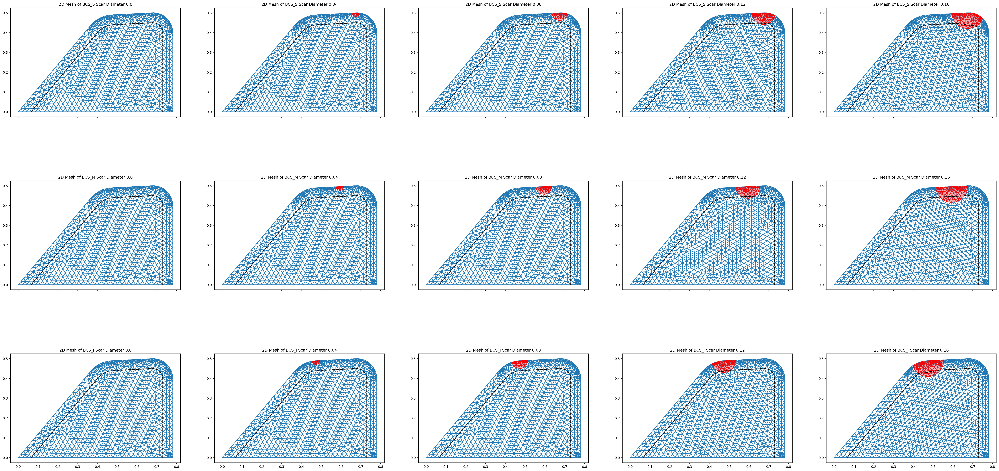

In [8]:
from matplotlib.tri import Triangulation
from femvf.meshutils import extract_zplane_facets

# Create grid of subplots to display meshes (at least for testing purposes)
fig, axs = plt.subplots(len(MeshNames), len(ScarDias), sharex=True, sharey=False, figsize=(48, 24))

for iM in range(0, len(MeshNames)):
    for iS in range(0, len(ScarDias)):
        # Extract full triangle data
        # cells = MESH[iM][iS].cells()
        coords = MESH[iM][iS].coordinates()

        # Plot triangular meshes
        axs[iM, iS].triplot(coords[:, 0], coords[:, 1], triangles=CELLS[iM][iS])
        # Plot body-cover interface
        axs[iM, iS].plot(VERT_INT[iM][iS][:, 0], VERT_INT[iM][iS][:, 1], color='k', linewidth=2, linestyle='--')
        if ScarDias[iS] > 0:
            # Highlight cells in scar region in red
            axs[iM, iS].triplot(VERT_SCAR[iM][iS][:, 0], VERT_SCAR[iM][iS][:, 1], triangles=CELLS_SCAR[iM][iS], color=[1, 0, 0], linewidth=1)
            # Fill the scar region faintly in red
            axs[iM, iS].fill(VERT_SCAR_BORDER[iM][iS][:, 0], VERT_SCAR_BORDER[iM][iS][:, 1], color=[1, 0, 0, 0.3])
            
        axs[iM, iS].set_aspect('equal')
        axs[iM, iS].set_title('2D Mesh of ' + MeshNames[iM] + ' Scar Diameter ' + str(ScarDias[iS]))

if SAVE_FIGS:
    fig.savefig(f'{FIG_DIR}/Meshes.{FIG_EXT}')

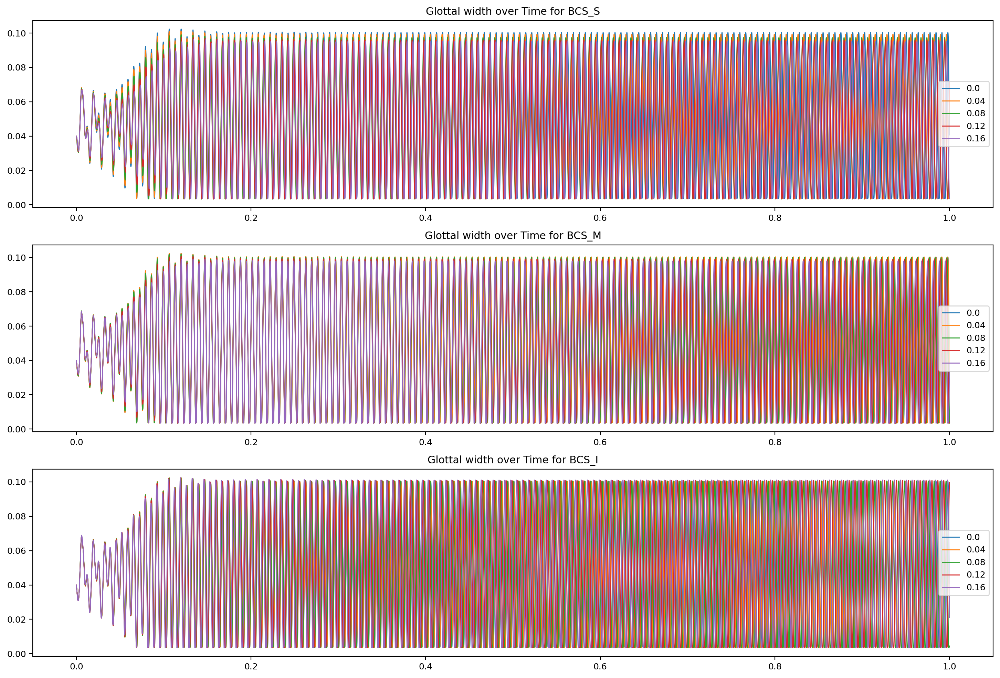

In [9]:
# Scar locations are on different plots, but scar diameters plotted together for comparison 
fig, axs = plt.subplots(len(MeshNames), 1, sharex=False, sharey=False, figsize=(18, 12))

for iM in range(0, len(MeshNames)):
    for iS in range(0, len(ScarDias)):
        t = load_measures(SIGNALS, f'time.t', {'MeshName': MeshNames[iM], 'SD': ScarDias[iS]})
        gw = load_measures(SIGNALS, f'time.gw', {'MeshName': MeshNames[iM], 'SD': ScarDias[iS]})
        
        axs[iM].set_title('Glottal width over Time for ' + MeshNames[iM])
        axs[iM].plot(t, gw, linewidth=1, linestyle='-')
        axs[iM].legend(ScarDias, loc='right')

        # Exporting gw and time to a csv file
        # df = pd.DataFrame({'glottal_gap' : gw, 'time' : t})
        # if SAVE_FIGS:
        #     df.to_csv(FIG_DIR + '/'+ str(f'{escar:.2e}') + '_glottal_gap.csv', index=False)

### Additional post-processing

In [10]:
## Post-process stress fields at fixed points
from femvf import static
from femvf.postprocess.solid import StressVonMisesField, StressHydrostaticField

for iM in range(0, len(MeshNames)):
    for iS in range(0, len(ScarDias)):
        svm_field = StressVonMisesField(MODEL[iM][iS])
        shydro_field = StressHydrostaticField(MODEL[iM][iS])

        _, controls, prop = scar.setup_state_control_props(PARAMS[iM][iS], MODEL[iM][iS])
        control = controls[0]
        MODEL[iM][iS].set_prop(prop)
        MODEL[iM][iS].dt = 1e6

        state_fp = scar.setup_ini_state(PARAMS[iM][iS], MODEL[iM][iS])
        svm = svm_field(state_fp, control, prop)
        shydro = shydro_field(state_fp, control, prop)


        SIGNALS['/field_fp_vm'] = svm
        # Save the fixed-point von Mises/hydrostatic stresses
        SIGNALS[f'{PARAMS[iM][iS].to_str()}/field_fp_vm'] = svm
        SIGNALS[f'{PARAMS[iM][iS].to_str()}/field_fp_hydrostatic'] = shydro

### Scalar Parameters

In [11]:
import ufl
_sig_update = {}

# Define arrays that are used for plotting results
F0_array = np.empty((len(MeshNames), len(ScarDias)), dtype='float64')
amp_array = np.empty((len(MeshNames), len(ScarDias)), dtype='float64')
SPL_array = np.empty((len(MeshNames), len(ScarDias)), dtype='float64')
OQ_array = np.empty((len(MeshNames), len(ScarDias)), dtype='float64')
MADR_array = np.empty((len(MeshNames), len(ScarDias)), dtype='float64')
MFDR_array = np.empty((len(MeshNames), len(ScarDias)), dtype='float64')

for iM in range(0, len(MeshNames)):
    for iS in range(0, len(ScarDias)):
        dx = get_dx(MODEL[iM][iS])
        dx_cover = get_dx(MODEL[iM][iS], 'cover')
        _f = dfn.Function(MODEL[iM][iS].solid.residual.form['coeff.prop.emod'].function_space())
        
        ## Add region averaged measures of stress fields
        stress_field_keys = {'field_tini_vm', 'field_tavg_vm', 'field_fp_vm'}
        for stress_field_key in stress_field_keys:
            key = f'{PARAMS[iM][iS].to_str()}/{stress_field_key}'
            if key in SIGNALS:
                try:
                    _f.vector()[:] = SIGNALS[key]
                    cover_vol = dfn.assemble(1*dx_cover)
                    _sig_update[f'{PARAMS[iM][iS].to_str()}/cover_avg_{stress_field_key}'] = dfn.assemble(_f*dx_cover)/cover_vol
                except:
                    pass
        
        # TODO change all calls to load_measures to SIGNALS[f'{PARAMS..., much more condensed
        # t = load_measures(SIGNALS, f'time.t', {'MeshName': MeshNames[iM], 'SD': ScarDias[iS]}) # Time
        t = SIGNALS[f'{PARAMS[iM][iS].to_str()}/time.t']
        N = t.size//2 # Getting indices that corresponod to 2nd half of simulation runtime

        # gw = load_measures(SIGNALS, f'time.gw', {'MeshName': MeshNames[iM], 'SD': ScarDias[iS]}) # Glottal Width
        gw = SIGNALS[f'{PARAMS[iM][iS].to_str()}/time.gw']
        q = SIGNALS[f'{PARAMS[iM][iS].to_str()}/time.q'] # Glottal flow rate

        t = t[-N:]
        gw = gw[-N:] # taking second half of simulation time as steady state data
        q = q[-N:]
        
        dt = t[1]-t[0]

        ## Fundamental Frequency
        fund_freq, fund_phase, dfreq, dphase, info = modal.fundamental_mode_from_peaks(gw, dt, height=np.max(gw)*0.8)
        _sig_update[f'{PARAMS[iM][iS].to_str()}/fund_freq'] = fund_freq
        _sig_update[f'{PARAMS[iM][iS].to_str()}/dfreq'] = dfreq
        _sig_update[f'{PARAMS[iM][iS].to_str()}/period_sample'] = 1/(fund_freq *dt)
        
        F0_array[iM][iS] = fund_freq
        
        ## Sound Pressure Level
        # Using piston in baffle approximation
        # Divide `prms` by 10 to get units of [Pa]
        prms = proc_prms(t, q)/10
        _sig_update[f'{PARAMS[iM][iS].to_str()}/prms'] = prms
        _sig_update[f'{PARAMS[iM][iS].to_str()}/spl'] = 20*np.log10(prms/20e-6)
        SPL_array[iM][iS] = _sig_update[f'{PARAMS[iM][iS].to_str()}/spl']
        
        ##  Vibration amplitude
        _sig_update[f'{PARAMS[iM][iS].to_str()}/amplitude'] = gw.max()-gw.min()
        amp_array[iM][iS] = _sig_update[f'{PARAMS[iM][iS].to_str()}/amplitude']
    
        ## Open Quotient
        # OQ is obtained by the amount of time where contact force is present
        savg_pc = SIGNALS[f'{PARAMS[iM][iS].to_str()}/time.spatial_stats_con_p']
        savg_pc = savg_pc[-N:] # taking second half of temporal data
        t_closed = len(np.nonzero(savg_pc)[0]) # Number of timesteps where contact forces are present
        
        OQ_array[iM][iS] = 1-t_closed/(len(t))
        
        ## Max Area Declination Rate
        # Using 2nd order accurate numpy.gradient function
        MADR_array[iM][iS] = min(np.gradient(gw, t))

        MFDR_array[iM][iS] = min(np.gradient(q, t))
        
SIGNALS.update(_sig_update)

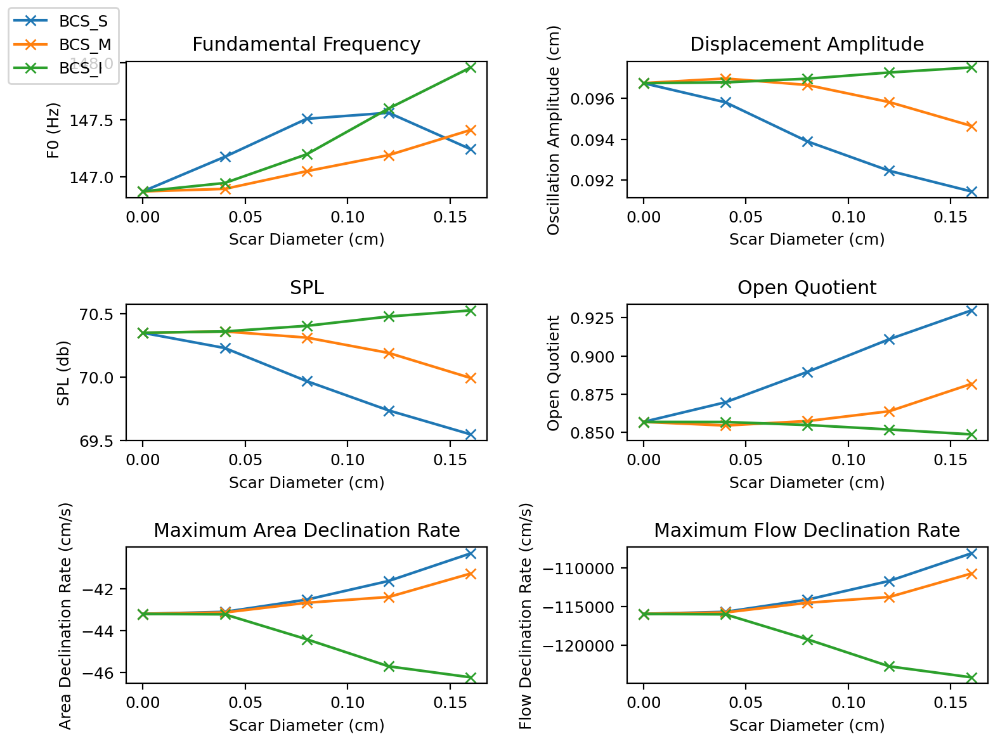

In [12]:
## Plot F0, Amplitude, SPL and OQ for all cases
fig, axs = plt.subplots(3, 2, sharex=False, sharey=False, figsize=(8, 6))
for iM in range(0, len(MeshNames)):
    # # Create total plot, dimensions are length, width
    axs[0, 0].set_title('Fundamental Frequency')
    axs[0, 0].set_xlabel('Scar Diameter (cm)')
    axs[0, 0].set_ylabel('F0 (Hz)')
    axs[0, 0].plot(ScarDias, F0_array[iM,:], marker='x')
        
    axs[0, 1].set_title('Displacement Amplitude')
    axs[0, 1].set_xlabel('Scar Diameter (cm)')
    axs[0, 1].set_ylabel('Oscillation Amplitude (cm)')
    axs[0, 1].plot(ScarDias, amp_array[iM,:], marker='x')
    
    axs[1, 0].set_title('SPL')
    axs[1, 0].set_xlabel('Scar Diameter (cm)')
    axs[1, 0].set_ylabel('SPL (db)')
    axs[1, 0].plot(ScarDias, SPL_array[iM,:], marker='x')

    axs[1, 1].set_title('Open Quotient')
    axs[1, 1].set_xlabel('Scar Diameter (cm)')
    axs[1, 1].set_ylabel('Open Quotient')
    axs[1, 1].plot(ScarDias, OQ_array[iM,:], marker='x')
    
    axs[2, 0].set_title('Maximum Area Declination Rate')
    axs[2, 0].set_xlabel('Scar Diameter (cm)')
    axs[2, 0].set_ylabel('Area Declination Rate (cm/s)')
    axs[2, 0].plot(ScarDias, MADR_array[iM,:], marker='x')
    
    axs[2, 1].set_title('Maximum Flow Declination Rate')
    axs[2, 1].set_xlabel('Scar Diameter (cm)')
    axs[2, 1].set_ylabel('Flow Declination Rate (cm/s)')
    axs[2, 1].plot(ScarDias, MFDR_array[iM,:], marker='x')

fig.legend(MeshNames, loc='upper left')
fig.tight_layout(pad=2)
if SAVE_FIGS:
    fig.savefig(f'{FIG_DIR}/Phonatory.{FIG_EXT}')

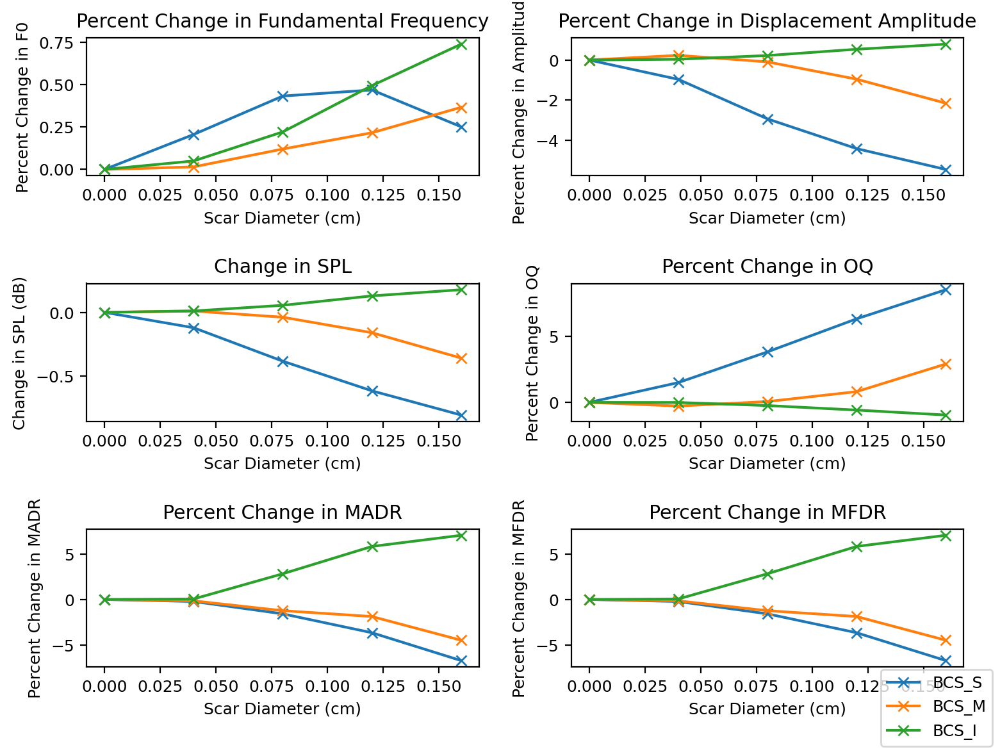

In [13]:
# Differences in preliminary variables
dF0_array = (F0_array[:, :] - F0_array[0, 0])/F0_array[0, 0]*100
dAmp_array = (amp_array[:, :] - amp_array[0, 0])/amp_array[0, 0]*100

# SPL difference is calculated differently, directly calculating flat change in SPL makes more sense considering measurement of decibels
# dSPL_array = (SPL_array[:, :] - SPL_array[0, 0])/SPL_array[0, 0]*100 # Old percent change difference
dSPL_array = SPL_array[:, :] - SPL_array[0, 0]
dOQ_array = (OQ_array[:, :] - OQ_array[0, 0])/OQ_array[0, 0]*100
dMADR_array = (MADR_array[:, :] - MADR_array[0, 0])/MADR_array[0, 0]*100
dMFDR_array = (MFDR_array[:, :] - MFDR_array[0, 0])/MFDR_array[0, 0]*100

## Plot differences in all variables
fig, axs = plt.subplots(3, 2, sharex=False, sharey=False, figsize=(8, 6))
for iM in range(0, len(MeshNames)):
    # # Create total plot, dimensions are length, width
    axs[0, 0].set_title('Percent Change in Fundamental Frequency')
    axs[0, 0].set_xlabel('Scar Diameter (cm)')
    axs[0, 0].set_ylabel('Percent Change in F0')
    axs[0, 0].plot(ScarDias, dF0_array[iM,:], marker='x')
        
    axs[0, 1].set_title('Percent Change in Displacement Amplitude')
    axs[0, 1].set_xlabel('Scar Diameter (cm)')
    axs[0, 1].set_ylabel('Percent Change in Amplitude')
    axs[0, 1].plot(ScarDias, dAmp_array[iM,:], marker='x')

    # axs[1, 0].set_title('Percent Change in SPL') # Old Percent change title for SPL
    axs[1, 0].set_title('Change in SPL')
    axs[1, 0].set_xlabel('Scar Diameter (cm)')
    # axs[1, 0].set_ylabel('Percent Change in SPL') # Old Percent change Y label for SPL
    axs[1, 0].set_ylabel('Change in SPL (dB)')
    axs[1, 0].plot(ScarDias, dSPL_array[iM,:], marker='x')

    axs[1, 1].set_title('Percent Change in OQ')
    axs[1, 1].set_xlabel('Scar Diameter (cm)')
    axs[1, 1].set_ylabel('Percent Change in OQ')
    axs[1, 1].plot(ScarDias, dOQ_array[iM,:], marker='x')
    
    axs[2, 0].set_title('Percent Change in MADR')
    axs[2, 0].set_xlabel('Scar Diameter (cm)')
    axs[2, 0].set_ylabel('Percent Change in MADR')
    axs[2, 0].plot(ScarDias, dMADR_array[iM,:], marker='x')
    
    axs[2, 1].set_title('Percent Change in MFDR')
    axs[2, 1].set_xlabel('Scar Diameter (cm)')
    axs[2, 1].set_ylabel('Percent Change in MFDR')
    axs[2, 1].plot(ScarDias, dMFDR_array[iM,:], marker='x')

fig.legend(MeshNames, loc='lower right')
fig.tight_layout(pad=2)
if SAVE_FIGS:
    fig.savefig(f'{FIG_DIR}/PhonatoryPercent.{FIG_EXT}')

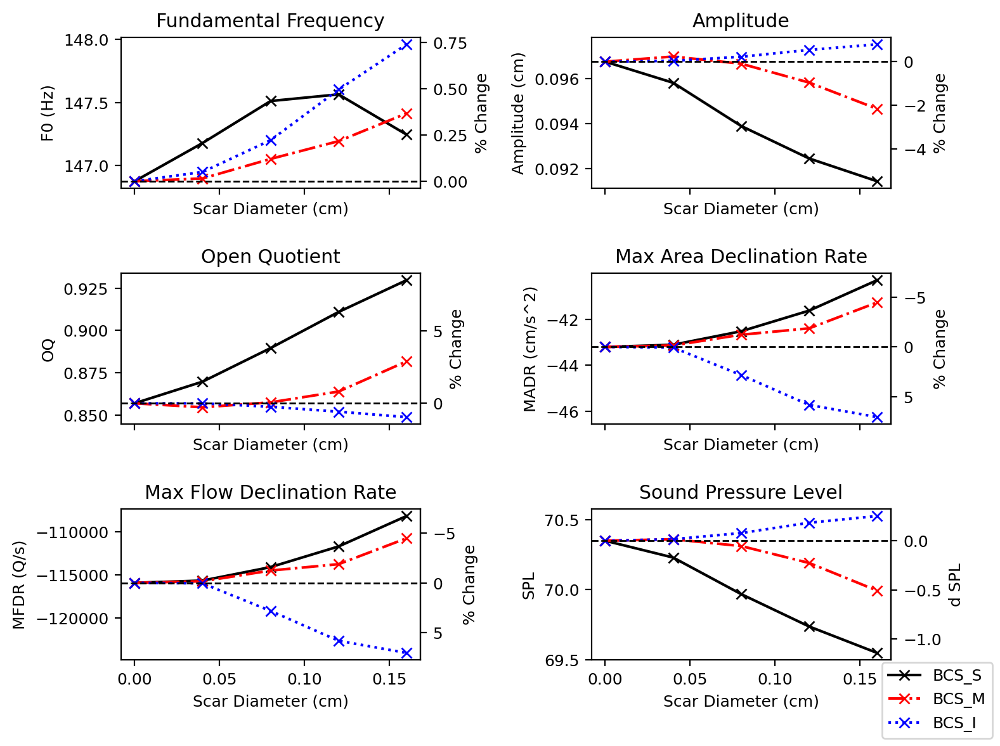

In [14]:
## Plot data with raw value on left y axis, percent change on right y axis
fig, axs = plt.subplots(3, 2, sharex=True, sharey=False, figsize=(8, 6))

# Function that creates the raw-percent val relation for any input tensor
def percentage_functions(yVals):
    ref = yVals[ScarDias.index(0)]
    def rawToPer(x):
        return (x - ref) / ref * 100
    def perToRaw(x):
        return (ref * x / 100) + ref
    return rawToPer, perToRaw

def absolute_functions(yVals):
    ref = yVals[ScarDias.index(0)]
    def rawToDiff(x):
        return (x - ref) / ref * 100
    def diffToRaw(x):
        return (ref * x / 100) + ref
    return rawToDiff, diffToRaw


pos = 0
for data in [F0_array, amp_array, OQ_array, MADR_array, MFDR_array]:
    axs[pos//2, pos%2].set_prop_cycle(THEME) # Copy theme from FIGURES section
    axs[pos//2, pos%2].set_xlabel('Scar Diameter (cm)') # All use same x axis    
    axs[pos//2, pos%2].plot(ScarDias, data.T, marker='x') # Plot data, transposed data to plot all iM cases at same time
    y2 = axs[pos//2, pos%2].secondary_yaxis('right', functions=percentage_functions(data[0,:])) # Add percentage diff function
    y2.set_ylabel('% Change') # Add percentage label
    axs[pos//2, pos%2].axhline(y=data[0,ScarDias.index(0)], color='k', linestyle='--', linewidth=1) # Add horizontal line along BC condition

    pos += 1

# Setting title and y axis titles specific to each type of data
axs[0, 0].set_title('Fundamental Frequency')
axs[0, 0].set_ylabel('F0 (Hz)')
axs[0, 1].set_title('Amplitude')
axs[0, 1].set_ylabel('Amplitude (cm)')
axs[1, 0].set_title('Open Quotient')
axs[1, 0].set_ylabel('OQ')
axs[1, 1].set_title('Max Area Declination Rate')
axs[1, 1].set_ylabel('MADR (cm/s^2)')
axs[2, 0].set_title('Max Flow Declination Rate')
axs[2, 0].set_ylabel('MFDR (Q/s)')
    

# Plotting SPL separately due to different way "difference" is shown
axs[2, 1].set_prop_cycle(THEME)
axs[2, 1].set_xlabel('Scar Diameter (cm)')
axs[2, 1].plot(ScarDias, SPL_array.T, marker='x')
y2 = axs[2, 1].secondary_yaxis('right', functions=absolute_functions(SPL_array[0,:]))
y2.set_ylabel('d SPL')
axs[2, 1].axhline(y=SPL_array[0,ScarDias.index(0)], color='k', linestyle='--', linewidth=1)
axs[2, 1].set_title('Sound Pressure Level')
axs[2, 1].set_ylabel('SPL')

fig.legend(MeshNames, loc='lower right')
fig.tight_layout(pad=2)
if SAVE_FIGS:
    fig.savefig(f'{FIG_DIR}/Phonatory_Final.{FIG_EXT}')

## Contact Stresses

In [15]:
residual = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
mesh = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
facet_function = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
facet_data = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
dofmap = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]

# Coordinates of all facets along the surface, which is needed for the 2D plot
facet_coords = [[[] for i in range(len(ScarDias))] for j in range(len(MeshNames))]
facet_cell_neighbour_dofs = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]

# Coordinates transformed to s dimension (along length of surface in cm)
facet_s = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]

# Contact quotient
dat_cq = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]

# Contact pressure field
dat = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]

for iM in range(0, len(MeshNames)):
    for iS in range(0, len(ScarDias)):
        ## Compute the 's' coordinate for the DG0 contact pressure
        residual[iM][iS] = MODEL[iM][iS].solid.residual
        mesh[iM][iS] = residual[iM][iS].mesh()

        facet_function[iM][iS] = residual[iM][iS].mesh_function('facet')
        facet_data[iM][iS] = residual[iM][iS].mesh_function_label_to_value('facet')
        dofmap[iM][iS] = residual[iM][iS].form['coeff.prop.eta'].function_space().dofmap()

        # Find facets along the traction surface and associated DG0 dofs
        facet_cell_neighbour_idxs = []
        for facet in dfn.facets(mesh[iM][iS]):
        # get all facet ids and check if it is along the pressure surface
            facet_idx = facet.index()
            if facet_function[iM][iS][facet_idx] == facet_data[iM][iS]['pressure']:
                facet_coord = facet.midpoint().array()[:2]
                # Save the new surface coords and id to separate numpy lists (keep separate for sorting soon)
                facet_coords[iM][iS].append(facet_coord)
                
                cell_neighbour_idx = facet.entities(2)
                assert len(cell_neighbour_idx) == 1
                cell_neighbour_idx = cell_neighbour_idx[0]
                facet_cell_neighbour_idxs.append(cell_neighbour_idx)

        facet_coords[iM][iS] = np.array(facet_coords[iM][iS])
        facet_cell_neighbour_idxs = np.array(facet_cell_neighbour_idxs)
        facet_cell_neighbour_dofs[iM][iS] = np.array(dofmap[iM][iS].entity_dofs(mesh[iM][iS], 2, facet_cell_neighbour_idxs))
        
        # Sort the DG0 dofs in streamwise increasing order
        from femvf.meshutils import sort_vertices_by_nearest_neighbours
        
        idx_sort = sort_vertices_by_nearest_neighbours(facet_coords[iM][iS], np.array([0,0]))
        facet_coords[iM][iS] = facet_coords[iM][iS][idx_sort]
        
        facet_cell_neighbour_dofs[iM][iS] = facet_cell_neighbour_dofs[iM][iS][idx_sort]
        _facet_coords = np.concatenate([facet_coords[iM][iS], np.array([[0, 0]])], axis=0)
        ds = np.linalg.norm(_facet_coords[1:]-_facet_coords[:-1], axis=-1)

        # Surface facets are labeled by distance from inferior-lateral corner (base of VF slope)
        facet_s[iM][iS] = np.cumsum(ds)

        _dat_pcfield = load_measures_np(SIGNALS, 'field.tavg_pc', {'MeshName': MeshNames[iM], 'SD': ScarDias[iS]})
        _dat_pc = load_measures_np(SIGNALS, 'time.spatial_stats_con_p', {'MeshName': MeshNames[iM], 'SD': ScarDias[iS]})
        _dat_pa = load_measures_np(SIGNALS, 'time.spatial_stats_con_a', {'MeshName': MeshNames[iM], 'SD': ScarDias[iS]})

        # Obtain contact quotient (amount of time with contact, defined by where the contact pressure is non-zero)
        # This also accounts for the initial transient state, but is assumed to be negligible with sufficiently long simulation time
        dat_cq[iM][iS] = len(_dat_pa.nonzero())/len(_dat_pa)
        
        # Load the contact pressure field and account for averaging over contact times only
        # Convert the unit to kpa
        # If multiplying by `1/cq`, the contact pressure is averaged over contact only
        dat[iM][iS] = _dat_pcfield/10/1e3 * 1/dat_cq[iM][iS]

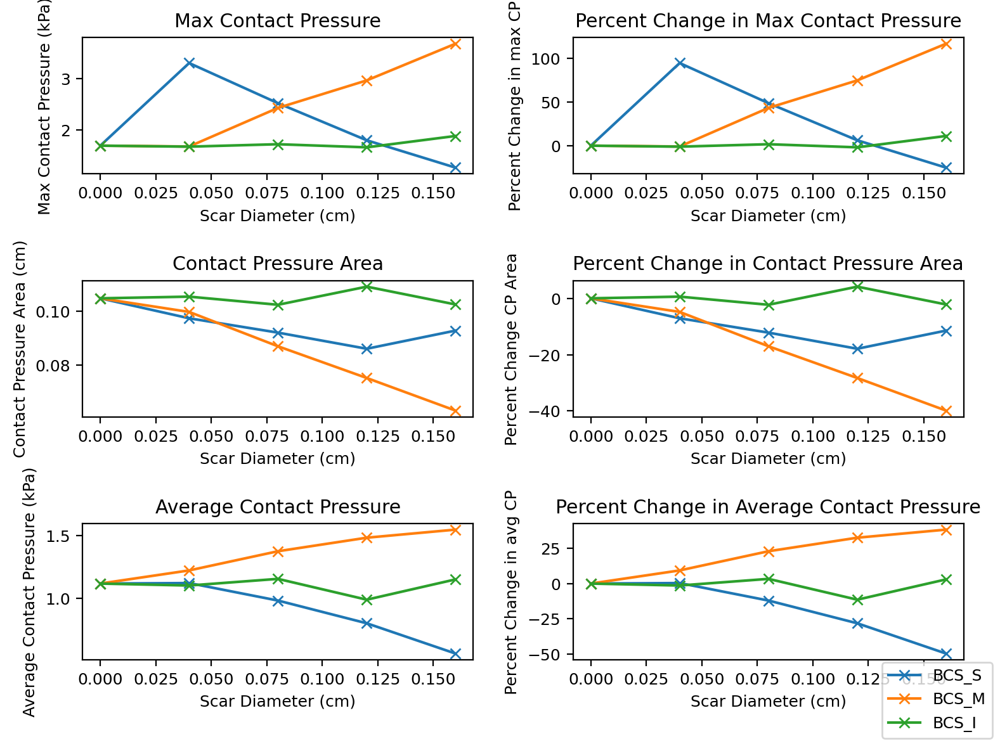

In [16]:
# Preliminary contact pressure data (max, average and contact area)
m_pc = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
dm_pc = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
avg_pc = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
davg_pc = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
area_pc = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
darea_pc = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]   

fig, axs = plt.subplots(3, 2, sharex=False, sharey=False, figsize=(8, 6))

for iM in range(0, len(MeshNames)):
    for iS in range(0, len(ScarDias)):
        ## Contact pressure
        # Convert to kPa
        pc = dat[iM][iS][facet_cell_neighbour_dofs[iM][iS]]/1e3
        m_pc[iM][iS] = max(pc)
        dm_pc[iM][iS] = (m_pc[iM][iS]-m_pc[0][0])/m_pc[0][0]*100

        # Use trapezoidal rule to obtain average force due to varying grid spacing along surface
        total_pc = np.trapezoid(pc, facet_s[iM][iS])
        # Find the glottal contact distance based on the min and max values where glottal force is found
        # not sure why facet_s[iM][iS] is technically a 2D array thats why taking min and max twice
        ds = (facet_s[iM][iS][max(max(np.nonzero(pc)))]-facet_s[iM][iS][min(min(np.nonzero(pc)))])
        area_pc[iM][iS] = ds
        avg_pc[iM][iS] = total_pc/area_pc[iM][iS]
        davg_pc[iM][iS] = (avg_pc[iM][iS]-avg_pc[0][0])/avg_pc[0][0]*100

        darea_pc[iM][iS] = (area_pc[iM][iS]-area_pc[0][0])/area_pc[0][0]*100
    # Plotting values
    axs[0, 0].set_title('Max Contact Pressure')
    axs[0, 0].set_xlabel('Scar Diameter (cm)')
    axs[0, 0].set_ylabel('Max Contact Pressure (kPa)')
    axs[0, 0].plot(ScarDias, m_pc[iM], marker='x')

    axs[0, 1].set_title('Percent Change in Max Contact Pressure')
    axs[0, 1].set_xlabel('Scar Diameter (cm)')
    axs[0, 1].set_ylabel('Percent Change in max CP')
    axs[0, 1].plot(ScarDias, dm_pc[iM], marker='x')

    axs[1, 0].set_title('Contact Pressure Area')
    axs[1, 0].set_xlabel('Scar Diameter (cm)')
    axs[1, 0].set_ylabel('Contact Pressure Area (cm)')
    axs[1, 0].plot(ScarDias, area_pc[iM], marker='x')

    axs[1, 1].set_title('Percent Change in Contact Pressure Area')
    axs[1, 1].set_xlabel('Scar Diameter (cm)')
    axs[1, 1].set_ylabel('Percent Change CP Area')
    axs[1, 1].plot(ScarDias, darea_pc[iM], marker='x')
    
    axs[2, 0].set_title('Average Contact Pressure')
    axs[2, 0].set_xlabel('Scar Diameter (cm)')
    axs[2, 0].set_ylabel('Average Contact Pressure (kPa)')
    axs[2, 0].plot(ScarDias, avg_pc[iM], marker='x')

    axs[2, 1].set_title('Percent Change in Average Contact Pressure')
    axs[2, 1].set_xlabel('Scar Diameter (cm)')
    axs[2, 1].set_ylabel('Percent Change in avg CP')
    axs[2, 1].plot(ScarDias, davg_pc[iM], marker='x')

fig.legend(MeshNames, loc='lower right')
fig.tight_layout(pad=2)
if SAVE_FIGS:
    fig.savefig(f'{FIG_DIR}/Contact.{FIG_EXT}')

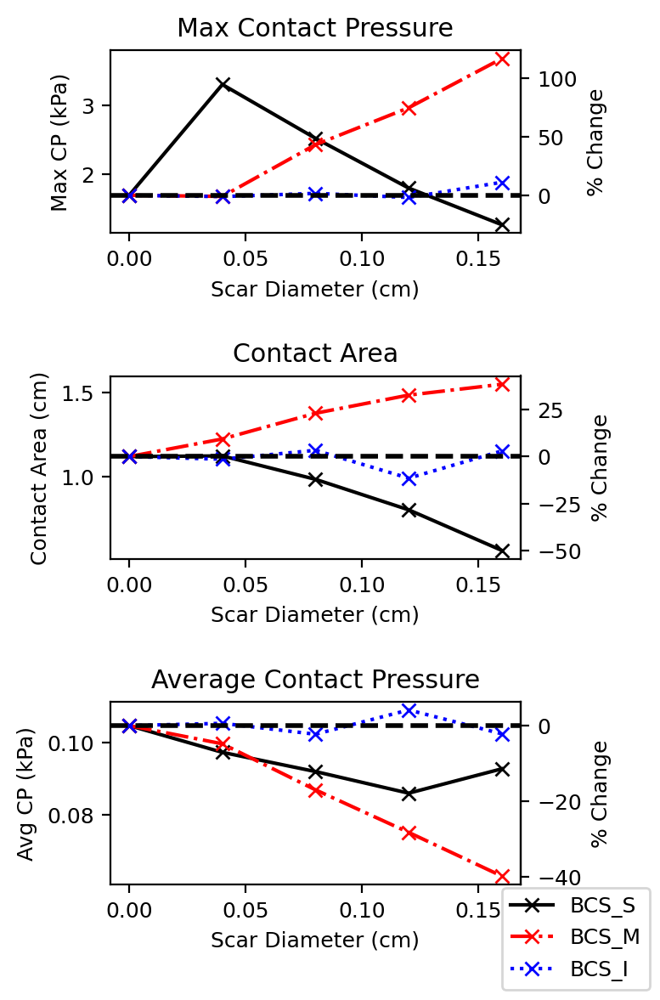

In [17]:
# Preliminary contact pressure data (max, average and contact area)
m_pc = np.empty((len(MeshNames), len(ScarDias)), dtype='float64')
avg_pc = np.empty((len(MeshNames), len(ScarDias)), dtype='float64')
area_pc = np.empty((len(MeshNames), len(ScarDias)), dtype='float64')

## Plot data with raw value on left y axis, percent change on right y axis
fig, axs = plt.subplots(3, sharex=False, sharey=False, figsize=(4, 6))

for iM in range(0, len(MeshNames)):
    for iS in range(0, len(ScarDias)):
        ## Contact pressure
        # Convert to kPa
        pc = dat[iM][iS][facet_cell_neighbour_dofs[iM][iS]]/1e3
        m_pc[iM, iS] = max(pc)

        # Use trapezoidal rule to obtain average force due to varying grid spacing along surface
        total_pc = np.trapezoid(pc, facet_s[iM][iS])
        # Find the glottal contact distance based on the min and max values where glottal force is found
        # not sure why facet_s[iM][iS] is technically a 2D array thats why taking min and max twice
        ds = (facet_s[iM][iS][max(max(np.nonzero(pc)))]-facet_s[iM][iS][min(min(np.nonzero(pc)))])
        area_pc[iM,iS] = ds
        avg_pc[iM,iS] = total_pc/area_pc[iM,iS]

# Function that creates the raw-percent val relation for any input tensor
def percentage_functions(yVals):
    ref = yVals[ScarDias.index(0)]
    def rawToPer(x):
        return (x - ref) / ref * 100
    def perToRaw(x):
        return (ref * x / 100) + ref
    return rawToPer, perToRaw

    
pos = 0
for data in [m_pc, avg_pc, area_pc]:
    axs[pos].set_prop_cycle(THEME) # Copy theme from FIGURES section
    axs[pos].set_xlabel('Scar Diameter (cm)') # All use same x axis    
    axs[pos].plot(ScarDias, data.T, marker='x') # Plot data, transposed data to plot all iM cases at same time
    y2 = axs[pos].secondary_yaxis('right', functions=percentage_functions(data[0,:])) # Add percentage diff function
    y2.set_ylabel('% Change') # Add percentage label
    axs[pos].axhline(y=data[0,ScarDias.index(0)], color='k', linestyle='--', linewidth=2) # Add horizontal line along BC condition

    pos += 1

# Setting title and y axis titles specific to each type of data
axs[0].set_title('Max Contact Pressure')
axs[0].set_ylabel('Max CP (kPa)')
axs[1].set_title('Contact Area')
axs[1].set_ylabel('Contact Area (cm)')
axs[2].set_title('Average Contact Pressure')
axs[2].set_ylabel('Avg CP (kPa)')

fig.legend(MeshNames, loc='lower right')
fig.tight_layout(pad=2)
if SAVE_FIGS:
    fig.savefig(f'{FIG_DIR}/ContactFinal.{FIG_EXT}')

/tmp/ipykernel_154157/671469078.py:36: UserWarning: tight_layout not applied: number of rows in subplot specifications must be multiples of one another.
  fig.tight_layout()


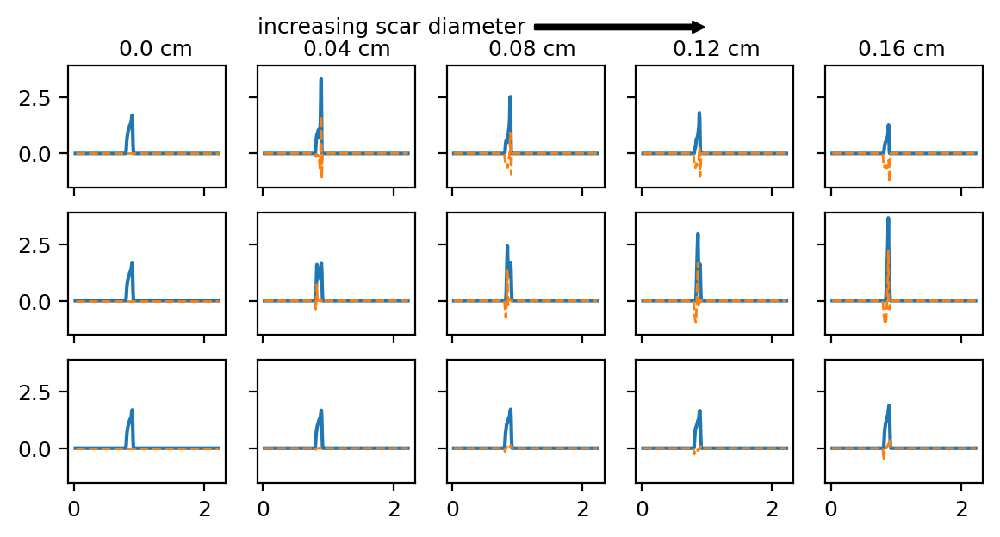

In [18]:
## Plot contact surface pressure profiles (line plot over 's' coordinate)
if FIG_TYPE == 'manuscript':
    fig, axs = plt.subplots(len(MeshNames), len(ScarDias), figsize=(FIG_LX_WIDE, 8*CM), sharex=True, sharey=True)
elif FIG_TYPE == 'presentation':
    fig, axs = plt.subplots(len(MeshNames), len(ScarDias), figsize=(FIG_LX_WIDE, FIG_LY), sharex=True, sharey=True)

for iM in range(0, len(MeshNames)):
    for iS in range(0, len(ScarDias)):
        # Convert to kPa
        pc_medial = dat[iM][iS][facet_cell_neighbour_dofs[iM][iS]]/1e3
        axs[iM][iS].plot(facet_s[iM][iS], pc_medial)

        # Interpolate baseline contact pressures due to different number of nodes between meshes
        baseline_pc = dat[0][0][facet_cell_neighbour_dofs[0][0]]/1e3
        interp_bl_pc = np.interp(facet_s[iM][iS], facet_s[0][0], baseline_pc)
        dpc_medial = pc_medial-interp_bl_pc
        axs[iM][iS].plot(facet_s[iM][iS], dpc_medial, linestyle='--', linewidth=1)

# Add annotation for increasing scar diameter
gs_ann = mpl.gridspec.GridSpec(2, len(ScarDias), figure=fig)
ax_ann = fig.add_subplot(gs_ann[0, :])
ax_ann.axis('off')
# xytext are starting location for text position
# xy are the location for the arrow head
ax_ann.annotate(
    'increasing scar diameter', ha='right', va='center',
    xytext=(0.5, 1.2), xy=(0.7, 1.2), xycoords=ax_ann.transAxes,
    arrowprops={'arrowstyle':'simple', 'fc': 'black'}
)

for i in range (0, len(ScarDias)):
    ax_ann = fig.add_subplot(gs_ann[0, :])
    ax_ann.axis('off')
    ax_ann.text(0.055 + 5.05*ScarDias[i], 1.05, str(ScarDias[i]) + ' cm')

fig.tight_layout()
if SAVE_FIGS:
    fig.savefig(f'{FIG_DIR}/ContactSurface.{FIG_EXT}')

/tmp/ipykernel_154157/3160177623.py:66: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/tmp/ipykernel_154157/3160177623.py:66: UserWarning: tight_layout not applied: number of rows in subplot specifications must be multiples of one another.
  fig.tight_layout()


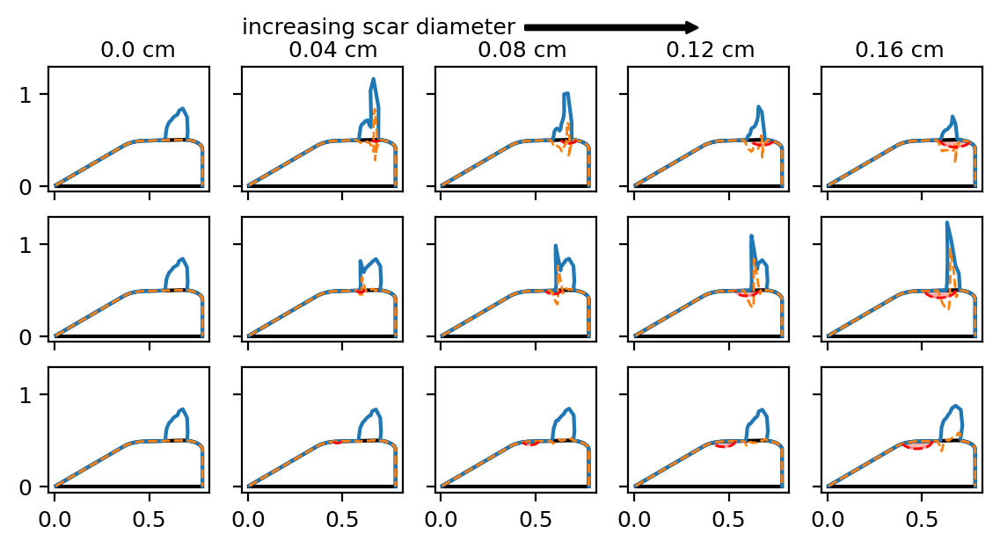

In [19]:
## Plot contact surface pressure profiles (spatial/fancy plot)
if FIG_TYPE == 'manuscript':
    fig, axs = plt.subplots(len(MeshNames), len(ScarDias), figsize=(FIG_LX_WIDE, 8*CM), sharex=True, sharey=True)
elif FIG_TYPE == 'presentation':
    fig, axs = plt.subplots(len(MeshNames), len(ScarDias), figsize=(FIG_LX_WIDE, FIG_LY), sharex=True, sharey=True)

# Define grid spacing
gs = mpl.gridspec.GridSpec(2, len(MeshNames), height_ratios=[0.1, 1], hspace=0.05)
ax_legend = fig.add_subplot(gs[0, :])
ax_legend.set_axis_off()

for iM in range(0, len(MeshNames)):
    for iS in range(0, len(ScarDias)):   
        xy_med = facet_coords[iM][iS]
        nn_med = normal(xy_med)
        # Plot VF mesh outline
        axs[iM, iS].plot(xy_med[:, 0], xy_med[:, 1], color='k')
        axs[iM, iS].plot(xy_med[[0, -1], 0], [0, 0], color='k')

        # get contact pressure data for offset from mesh
        pc_medial = dat[iM][iS][facet_cell_neighbour_dofs[iM][iS]]
        # Interpolate baseline contact pressures due to different number of nodes between meshes
        baseline_pc = dat[0][0][facet_cell_neighbour_dofs[0][0]]
        interp_bl_pc = np.interp(facet_s[iM][iS], facet_s[0][0], baseline_pc)
        dpc_medial = pc_medial-interp_bl_pc
        
        scale = -0.2e-3
        pc_norm = [[0, 0] for i in range(len(pc_medial))]
        for iPC in range(0, len(pc_medial)):
            pc_norm[iPC][0] = scale*pc_medial[iPC]*nn_med[iPC][0]
            pc_norm[iPC][1] = scale*pc_medial[iPC]*nn_med[iPC][1]

        dpc_norm = [[0, 0] for i in range(len(dpc_medial))]
        for iPC in range(0, len(dpc_medial)):
            dpc_norm[iPC][0] = scale*dpc_medial[iPC]*nn_med[iPC][0]
            dpc_norm[iPC][1] = scale*dpc_medial[iPC]*nn_med[iPC][1]
            
        pc_n = offset_normal(xy_med, pc_norm)
        axs[iM, iS].plot(pc_n[:, 0], pc_n[:, 1])
        
        dpc_n = offset_normal(xy_med, dpc_norm)
        axs[iM, iS].plot(dpc_n[:, 0], dpc_n[:, 1], linestyle='--', linewidth=1)

        # plot scar region if present
        if ScarDias[iS] > 0:
            axs[iM, iS].plot(VERT_SCAR_INT[iM][iS][:, 0], VERT_SCAR_INT[iM][iS][:, 1], color=[1, 0, 0], linestyle='--', linewidth=1)
            axs[iM, iS].fill(VERT_SCAR_BORDER[iM][iS][:, 0], VERT_SCAR_BORDER[iM][iS][:, 1], color=[1, 0, 0, 0.3])

# Add annotation for increasing scar diameter
gs_ann = mpl.gridspec.GridSpec(2, len(ScarDias), figure=fig)
ax_ann = fig.add_subplot(gs_ann[0, :])
ax_ann.axis('off')
# xytext are starting location for text position
# xy are the location for the arrow head
ax_ann.annotate(
    'increasing scar diameter', ha='right', va='center',
    xytext=(0.5, 1.2), xy=(0.7, 1.2), xycoords=ax_ann.transAxes,
    arrowprops={'arrowstyle':'simple', 'fc': 'black'}
)

for i in range (0, len(ScarDias)):
    ax_ann = fig.add_subplot(gs_ann[0, :])
    ax_ann.axis('off')
    ax_ann.text(0.055 + 5.05*ScarDias[i], 1.05, str(ScarDias[i]) + ' cm')

fig.tight_layout()
if SAVE_FIGS:
    fig.savefig(f'{FIG_DIR}/Contact2D.{FIG_EXT}')

## 2D Stress Fields

In [20]:
## Parsing VM Data
vm_vertex = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
dvm_vertex = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]

# Getting data from BC simulation to be projected onto each scar case
vm_bc=np.array([load_measures_np(SIGNALS, f'field.tavg_vm', {'MeshName': MeshNames[0], 'SD': ScarDias[0]})])[0]/10/1e3
fspace_cg1_bc = dfn.FunctionSpace(MODEL[0][0].solid.residual.mesh(), 'CG', 1)#forms['fspace.scalar']
fspace_dg0_bc = dfn.FunctionSpace(MODEL[0][0].solid.residual.mesh(), 'DG', 0)
z_cg1_bc = dfn.Function(fspace_cg1_bc)
z_dg0_bc = dfn.Function(fspace_dg0_bc)
vm_bc_flat = vm_bc.reshape(-1, vm_bc.shape[-1])
z_dg0_bc.vector()[:] = vm_bc

for iM in range(0, len(MeshNames)):
    for iS in range(0, len(ScarDias)):
        # VERT_TO_VDOF, CELLS are defined early on in notebook when loading model info, dependent on the meshes
        # XREF_VERT = XREF[iM][iS][VERT_TO_VDOF[iM][iS]].reshape(-1, 2)
        # trian = tri.Triangulation(XREF_VERT[:, 0], XREF_VERT[:, 1], CELLS[iM][iS])

        data_vm_raw = load_measures_np(SIGNALS, f'field.tavg_vm', {'MeshName': MeshNames[iM], 'SD': ScarDias[iS]})
        data_vm = np.array(data_vm_raw)/10/1e3
        # ys_abs = np.array([load_measures_np(SIGNALS, f'field.tavg_vm', {'MeshName': MeshNames[iM], 'SD': ScarDias[iS]})])[0]/10/1e3
        # ys_abs_flat = ys_abs.reshape(-1, ys_abs.shape[-1])
        
        fspace_cg1 = dfn.FunctionSpace(MODEL[iM][iS].solid.residual.mesh(), 'CG', 1)#forms['fspace.scalar']
        fspace_dg0 = dfn.FunctionSpace(MODEL[iM][iS].solid.residual.mesh(), 'DG', 0)
        z_cg1 = dfn.Function(fspace_cg1)
        z_dg0 = dfn.Function(fspace_dg0)    
    
        ## Project the dg0 stress to CG1 so you can plot contours
        z_dg0.vector()[:] = data_vm
        vm_vertex[iM][iS] = dfn.project(z_dg0, fspace_cg1, function=z_cg1).vector()[VERT_TO_SDOF[iM][iS]]
        # z_vertex = dfn.project(z_dg0, fspace_cg1, function=z_cg1).vector()[VERT_TO_SDOF[iM][iS]]

        # Project BC VM data onto current scar geometry
        vm_vertex_bc = dfn.project(z_dg0_bc, fspace_cg1, function=z_cg1).vector()[VERT_TO_SDOF[iM][iS]]
        dvm_vertex[iM][iS] = vm_vertex[iM][iS]-vm_vertex_bc

# Breaking up for loops allows searching for min and max values across all cases
# TODO fix zmin and zmax, not getting values across all dimensions of dz_vertex
# zmin = np.min(dz_vertex)
# zmax = np.max(dz_vertex)

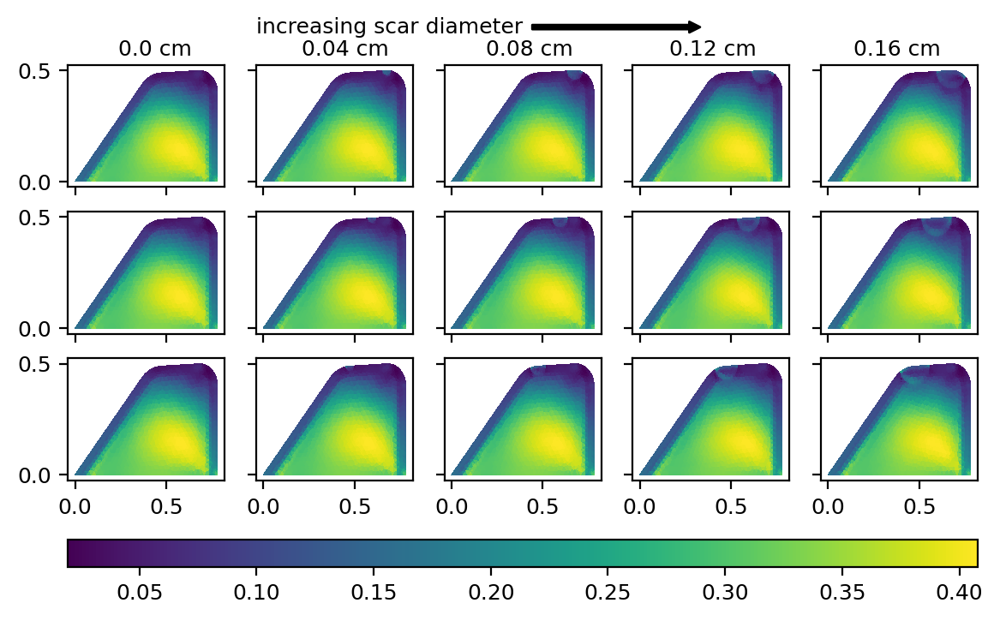

In [21]:
# Generating VM stress plots
import matplotlib.colorizer as mcolorizer
import matplotlib.colors as mcolors

if FIG_TYPE == 'manuscript':
    fig, axs = plt.subplots(len(MeshNames), len(ScarDias), figsize=(FIG_LX_WIDE, 8*CM), sharex=True, sharey=True)
elif FIG_TYPE == 'presentation':
    fig, axs = plt.subplots(len(MeshNames), len(ScarDias), figsize=(FIG_LX_WIDE, FIG_LY), sharex=True, sharey=True)

# Define grid spacing
gs = mpl.gridspec.GridSpec(2, len(MeshNames), height_ratios=[0.1, 1], hspace=0.05)

images = []

# TODO fix zmin and zmax, not getting values across all dimensions of dz_vertex
# zmin = np.min(dz_vertex)
# zmax = np.max(dz_vertex)
# kwargs = {'vmin': zmin, 'vmax': zmax, 'edgecolors': 'none'}
kwargs = {'edgecolors': 'none'}

for iM in range(0, len(MeshNames)):
    for iS in range(0, len(ScarDias)):
        XREF_VERT = XREF[iM][iS][VERT_TO_VDOF[iM][iS]].reshape(-1, 2)
        trian = tri.Triangulation(XREF_VERT[:, 0], XREF_VERT[:, 1], CELLS[iM][iS])
        images.append(axs[iM, iS].tripcolor(trian, vm_vertex[iM][iS][:], **kwargs))
        # plot scar region if present
        # if ScarDias[iS] > 0:
        #     axs[iM, iS].plot(VERT_SCAR_INT[iM][iS][:, 0], VERT_SCAR_INT[iM][iS][:, 1], color=[1, 0, 0], linestyle='--', linewidth=0.5)

# Add annotation for increasing scar diameter
gs_ann = mpl.gridspec.GridSpec(2, len(ScarDias), figure=fig)
ax_ann = fig.add_subplot(gs_ann[0, :])
ax_ann.axis('off')
# xytext are starting location for text position
# xy are the location for the arrow head
ax_ann.annotate(
    'increasing scar diameter', ha='right', va='center',
    xytext=(0.5, 1.2), xy=(0.7, 1.2), xycoords=ax_ann.transAxes,
    arrowprops={'arrowstyle':'simple', 'fc': 'black'}
)

for i in range (0, len(ScarDias)):
    ax_ann = fig.add_subplot(gs_ann[1, :])
    ax_ann.axis('off')
    ax_ann.text(0.055 + 5.05*ScarDias[i], 2.25, str(ScarDias[i]) + ' cm')

cbar_ax = fig.add_axes([0.125, -0.05, 0.775, 0.05])
fig.colorbar(images[0], cax=cbar_ax, orientation='horizontal', fraction=.1)

if SAVE_FIGS:
    fig.savefig(f'{FIG_DIR}/VM.{FIG_EXT}')

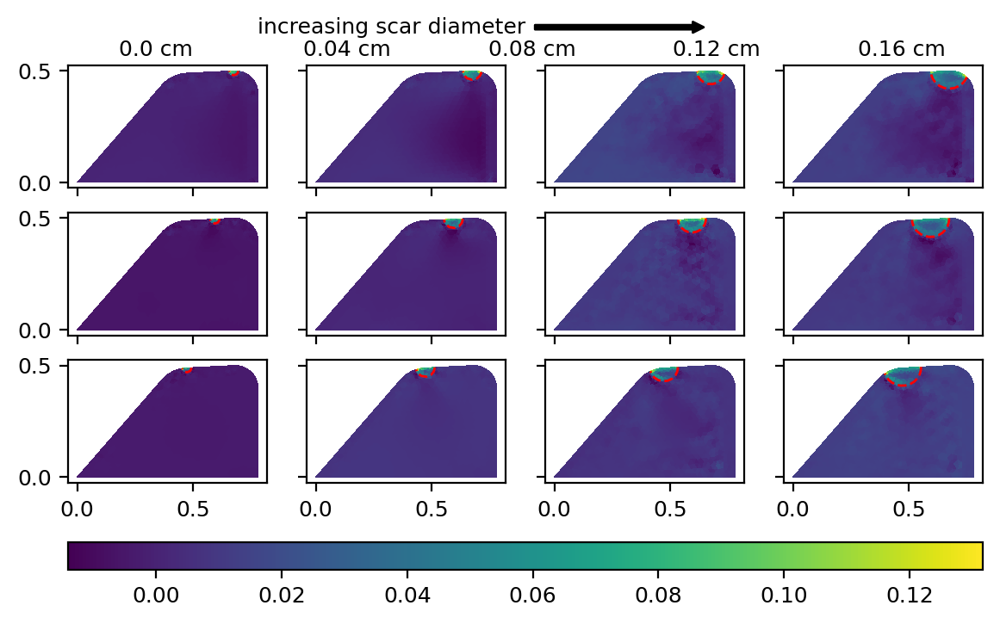

In [22]:
# Generating VM stress difference plots
if FIG_TYPE == 'manuscript':
    fig, axs = plt.subplots(len(MeshNames), len(ScarDias)-1, figsize=(FIG_LX_WIDE, 8*CM), sharex=True, sharey=True)
elif FIG_TYPE == 'presentation':
    fig, axs = plt.subplots(len(MeshNames), len(ScarDias)-1, figsize=(FIG_LX_WIDE, FIG_LY), sharex=True, sharey=True)

# Define grid spacing
gs = mpl.gridspec.GridSpec(2, len(MeshNames)-1, height_ratios=[0.1, 1], hspace=0.05)

images = []

# TODO fix zmin and zmax, not getting values across all dimensions of dz_vertex
# zmin = np.min(dz_vertex)
# zmax = np.max(dz_vertex)
# kwargs = {'vmin': zmin, 'vmax': zmax, 'edgecolors': 'none'}
kwargs = {'edgecolors': 'none'}

for iM in range(0, len(MeshNames)):
    for iS in range(1, len(ScarDias)):
        XREF_VERT = XREF[iM][iS][VERT_TO_VDOF[iM][iS]].reshape(-1, 2)
        trian = tri.Triangulation(XREF_VERT[:, 0], XREF_VERT[:, 1], CELLS[iM][iS])
        images.append(axs[iM, iS-1].tripcolor(trian, dvm_vertex[iM][iS][:], **kwargs))
        # plot scar region if present
        if ScarDias[iS] > 0:
            axs[iM, iS-1].plot(VERT_SCAR_INT[iM][iS][:, 0], VERT_SCAR_INT[iM][iS][:, 1], color=[1, 0, 0], linestyle='--', linewidth=1)

# Add annotation for increasing scar diameter
gs_ann = mpl.gridspec.GridSpec(2, len(ScarDias), figure=fig)
ax_ann = fig.add_subplot(gs_ann[0, :])
ax_ann.axis('off')
# xytext are starting location for text position
# xy are the location for the arrow head
ax_ann.annotate(
    'increasing scar diameter', ha='right', va='center',
    xytext=(0.5, 1.2), xy=(0.7, 1.2), xycoords=ax_ann.transAxes,
    arrowprops={'arrowstyle':'simple', 'fc': 'black'}
)

for i in range (0, len(ScarDias)):
    ax_ann = fig.add_subplot(gs_ann[1, :])
    ax_ann.axis('off')
    ax_ann.text(0.055 + 5.05*ScarDias[i], 2.25, str(ScarDias[i]) + ' cm')

cbar_ax = fig.add_axes([0.125, -0.05, 0.775, 0.05])
fig.colorbar(images[0], cax=cbar_ax, orientation='horizontal', fraction=.1)
if SAVE_FIGS:
    fig.savefig(f'{FIG_DIR}/VM_Diff.{FIG_EXT}')

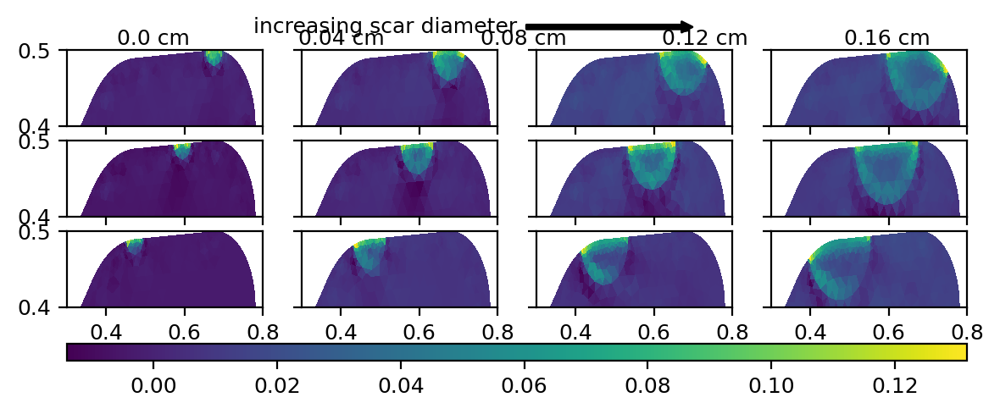

In [23]:
# VM Plots focusing on medial surfaces 
if FIG_TYPE == 'manuscript':
    fig, axs = plt.subplots(len(MeshNames), len(ScarDias)-1, figsize=(FIG_LX_WIDE, 5*CM), sharex=True, sharey=True)
elif FIG_TYPE == 'presentation':
    fig, axs = plt.subplots(len(MeshNames), len(ScarDias)-1, figsize=(FIG_LX_WIDE, FIG_LY), sharex=True, sharey=True)

# Define grid spacing
gs = mpl.gridspec.GridSpec(2, len(MeshNames)-1, height_ratios=[0.1, 1], hspace=0.05)

images = []

# TODO fix zmin and zmax, not getting values across all dimensions of dz_vertex
# zmin = np.min(dz_vertex)
# zmax = np.max(dz_vertex)
# kwargs = {'vmin': zmin, 'vmax': zmax, 'edgecolors': 'none'}
kwargs = {'edgecolors': 'none'}

for iM in range(0, len(MeshNames)):
    for iS in range(1, len(ScarDias)):
        XREF_VERT = XREF[iM][iS][VERT_TO_VDOF[iM][iS]].reshape(-1, 2)
        trian = tri.Triangulation(XREF_VERT[:, 0], XREF_VERT[:, 1], CELLS[iM][iS])
        axs[iM, iS-1].set(xlim=(0.3, 0.8), ylim=(0.4, 0.5))
        images.append(axs[iM, iS-1].tripcolor(trian, dvm_vertex[iM][iS][:], **kwargs))
        # plot scar region if present
        # if ScarDias[iS] > 0:
        #     axs[iM, iS-1].plot(VERT_SCAR_INT[iM][iS][:, 0], VERT_SCAR_INT[iM][iS][:, 1], color=[1, 0, 0], linestyle='--', linewidth=1)

# Add annotation for increasing scar diameter
gs_ann = mpl.gridspec.GridSpec(2, len(ScarDias), figure=fig)
ax_ann = fig.add_subplot(gs_ann[0, :])
ax_ann.axis('off')
# xytext are starting location for text position
# xy are the location for the arrow head
ax_ann.annotate(
    'increasing scar diameter', ha='right', va='center',
    xytext=(0.5, 1.2), xy=(0.7, 1.2), xycoords=ax_ann.transAxes,
    arrowprops={'arrowstyle':'simple', 'fc': 'black'}
)

for i in range (0, len(ScarDias)):
    ax_ann = fig.add_subplot(gs_ann[1, :])
    ax_ann.axis('off')
    ax_ann.text(0.055 + 5.05*ScarDias[i], 2.25, str(ScarDias[i]) + ' cm')

cbar_ax = fig.add_axes([0.125, -0.05, 0.775, 0.05])
fig.colorbar(images[0], cax=cbar_ax, orientation='horizontal', fraction=.1)
if SAVE_FIGS:
    fig.savefig(f'{FIG_DIR}/VM_Diff_Medial.{FIG_EXT}')

MovieWriter ffmpeg unavailable; using Pillow instead.


ValueError: unknown file extension: .mp4

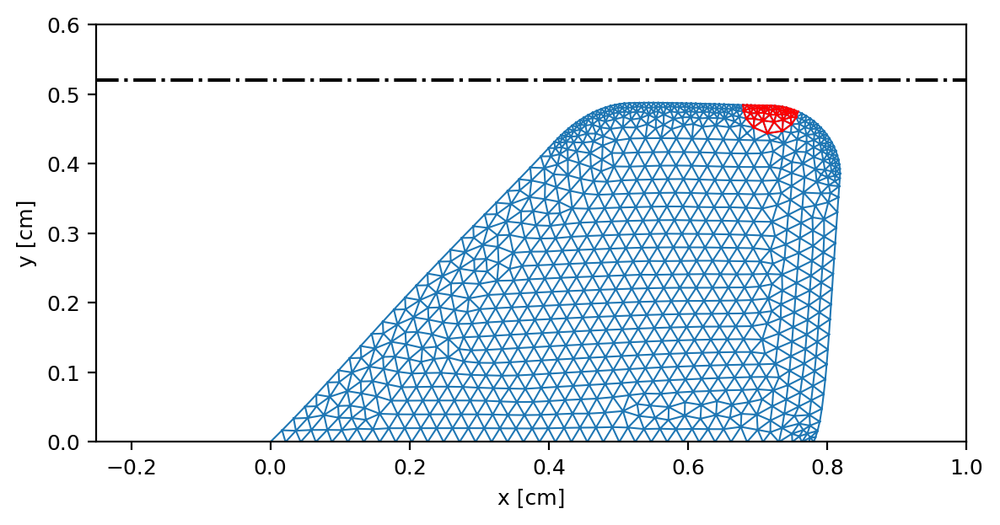

In [24]:
def tri_to_linexy(tri):
    x, y, edges = (tri.x, tri.y, tri.edges)
    tri_lines_x = np.insert(x[edges], 2, np.nan, axis=1).ravel()
    tri_lines_y = np.insert(y[edges], 2, np.nan, axis=1).ravel()
    return tri_lines_x, tri_lines_y

def plot_update(f, t, offset, plot_1, plot_2, dt, iM, iS):    
    ii = int(round(t/dt))
    xcur = XREF[iM][iS] + f.get_state(offset+ii).sub['u']
    xcur_vert = xcur[VERT_TO_VDOF[iM][iS]].reshape(-1, 2)

    # mutate the triplot lines in artists[0]
    tri_frame = tri.Triangulation(xcur_vert[:, 0], xcur_vert[:, 1], CELLS[iM][iS])
    x, y = tri_to_linexy(tri_frame)
    plot_1[0].set_xdata(x)
    plot_1[0].set_ydata(y)
    
    tri_frame = tri.Triangulation(xcur_vert[:, 0], xcur_vert[:, 1], CELLS[iM][iS][CELLS_SCAR[iM][iS]])
    x, y = tri_to_linexy(tri_frame)
    plot_2[0].set_xdata(x)
    plot_2[0].set_ydata(y)
    return plot_2


# Figure dimensions
FIG_LX_WIDE = 12
FIG_LY = 8
SIZE_SMALL = 6

from scipy.signal import find_peaks
from matplotlib import animation

## Animate motionfig, axs = plt.subplots(len(MeshNames), len(ScarDias), figsize=(FIG_LX_WIDE, 8*CM), sharex=True, sharey=True)
fig, ax = plt.subplots(1, 1, figsize=(SIZE_SMALL, 8*CM))
ax.set_xlim(-0.25, 1.0)
ax.set_ylim(0, 0.6)
ax.set_xlabel('x [cm]')
ax.set_ylabel('y [cm]')
ax.set_aspect(1.0, adjustable='box')
# TODO change value to dynamically get centerline
ax.axhline(0.52, color='k', ls='-.')
fig.tight_layout()

XREF_VERT = XREF[0][2][VERT_TO_VDOF[0][2]].reshape(-1, 2)
trian = tri.Triangulation(XREF_VERT[:, 0], XREF_VERT[:, 1], CELLS[0][2])
trian_scar = tri.Triangulation(XREF_VERT[:, 0], XREF_VERT[:, 1], CELLS[0][2][CELLS_SCAR[0][2]])

trip_1 = ax.triplot(trian, lw=0.75)
trip_2 = ax.triplot(trian_scar, lw=0.75, color=[1, 0, 0])
# artists = ax.triplot(trian, lw=0.75)
# artists = [ax.triplot(trian, lw=0.75), ax.triplot(trian_scar, lw=0.75)]

t = [[0 for i in range(len(ScarDias))] for j in range(len(MeshNames))]
t[0][2] = load_measures_np(SIGNALS, f'time.t', {'MeshName': MeshNames[0], 'SD': ScarDias[2]})

# Change to get case using mesh indices for fname
with sf.StateFile(MODEL[0][2], f'{OUT_DIR}/{PARAMS[0][2].to_str()}.h5', mode='r') as f:
    def _plot_update(frame):
        dt = 1
        offset = 0
        return plot_update(f, frame, offset, trip_1, trip_2, dt, 0, 2)

    ani = animation.FuncAnimation(
        fig,
        _plot_update,
        blit=True,
        frames = range(9800, 10000)
    )

    SD = ScarDias[2]
    meshname = MeshNames[0]
    # if SAVE_FIGS:
    ani.save(f'{FIG_DIR}/MeshName{meshname}_SD{SD:.2e}_2.mp4', dpi=450, fps=60)
